# Tarea 3 — Sistemas Dinámicos
## Pesquería con Esfuerzo Constante
**Estudiante 6 · María Paz Rojas C.· Formación en Clima / Hidrología**

## Requisitos para reproducir este notebook

**Python:** 3.9 o superior

**Librerías** (incluidas en cualquier distribución científica estándar como Anaconda):

| Librería | Uso |
|---|---|
| `numpy` | Arreglos numéricos y funciones matemáticas |
| `matplotlib` | Generación de gráficos |
| `scipy` | Integración numérica de la ODE (`solve_ivp`) |

En caso de no tenerlas instaladas, ejecutar en terminal: pip install numpy matplotlib scipy

**Para ejecutar:** abrir en Jupyter Notebook o JupyterLab y seleccionar
**Kernel → Restart & Run All**. La figura de 4 paneles se guardará automáticamente
como `pesqueria_analisis.png` en la misma carpeta del notebook.


### 1. Modelo e interpretación

El modelo canónico de gestión de un recurso renovable es:

$$\dot{N} = rN\left(1 - \frac{N}{K}\right) - EN$$

| Parámetro | Significado | Analogía hidrológica |
|-----------|-------------|----------------------|
| $N(t)$    | Stock del recurso (población) | Nivel de un acuífero |
| $r$       | Tasa de crecimiento intrínseca | Tasa de recarga natural |
| $K$       | Capacidad de carga | Volumen máximo del acuífero |
| $E$       | Esfuerzo de extracción (constante) | Tasa de bombeo |
| $rN(1-N/K)$ | Crecimiento logístico | Recarga neta dependiente del nivel |
| $EN$      | Cosecha proporcional al stock | Extracción proporcional al nivel disponible |

El término $EN$ implica que la extracción **escala con el recurso disponible**: 
si el stock cae, la cosecha también cae automáticamente.

---

### 2. Puntos fijos

Igualando $f(N) = 0$ y factorizando:

$$N\left[r\left(1 - \frac{N}{K}\right) - E\right] = 0$$

Se obtienen dos puntos fijos:

$$N_1^* = 0 \qquad \text{(agotamiento)}$$

$$N_2^* = K\left(1 - \frac{E}{r}\right) \qquad \text{(equilibrio no trivial)}$$

$N_2^*$ es positivo (físicamente válido) **solo cuando** $E < r$.

---

### 3. Estabilidad

Evaluando $f'(N^*)$ en cada punto fijo:

$$f'(N) = r - \frac{2rN}{K} - E$$

| Punto fijo | $f'(N^*)$ | Condición | Estabilidad |
|-----------|-----------|-----------|-------------|
| $N_1^* = 0$ | $r - E$ | $E < r$ | **Inestable** |
| $N_1^* = 0$ | $r - E$ | $E > r$ | **Estable** |
| $N_2^* = K(1-E/r)$ | $E - r$ | $E < r$ | **Estable** |

---

### 4. Bifurcación transcrítica

El parámetro de control es $E$. En el valor crítico $E_c = r$, 
los dos puntos fijos **colisionan en $N=0$ e intercambian estabilidad**.

$$E_c = r \quad \Rightarrow \quad N_2^* = K\left(1 - \frac{r}{r}\right) = 0$$

Esto es una **bifurcación transcrítica**: $N^* = 0$ pasa de inestable a estable 
al cruzar $E_c$. No hay histéresis — el sistema no tiene "memoria" del estado anterior.

**Rendimiento Máximo Sostenible (RMS):** maximizando $Y(E) = E \cdot N_2^* = EK(1-E/r)$:

$$\frac{dY}{dE} = K\left(1 - \frac{2E}{r}\right) = 0 \quad \Rightarrow \quad 
E_{RMS} = \frac{r}{2}, \quad Y_{RMS} = \frac{rK}{4}$$


[OK] El gráfico fue generado y guardado exitosamente en:
/Users/mariapazrojascastillo/Library/CloudStorage/Dropbox/01_doctorado/Class/ing_sistemas/Tarea 3/pesqueria_analisis.png



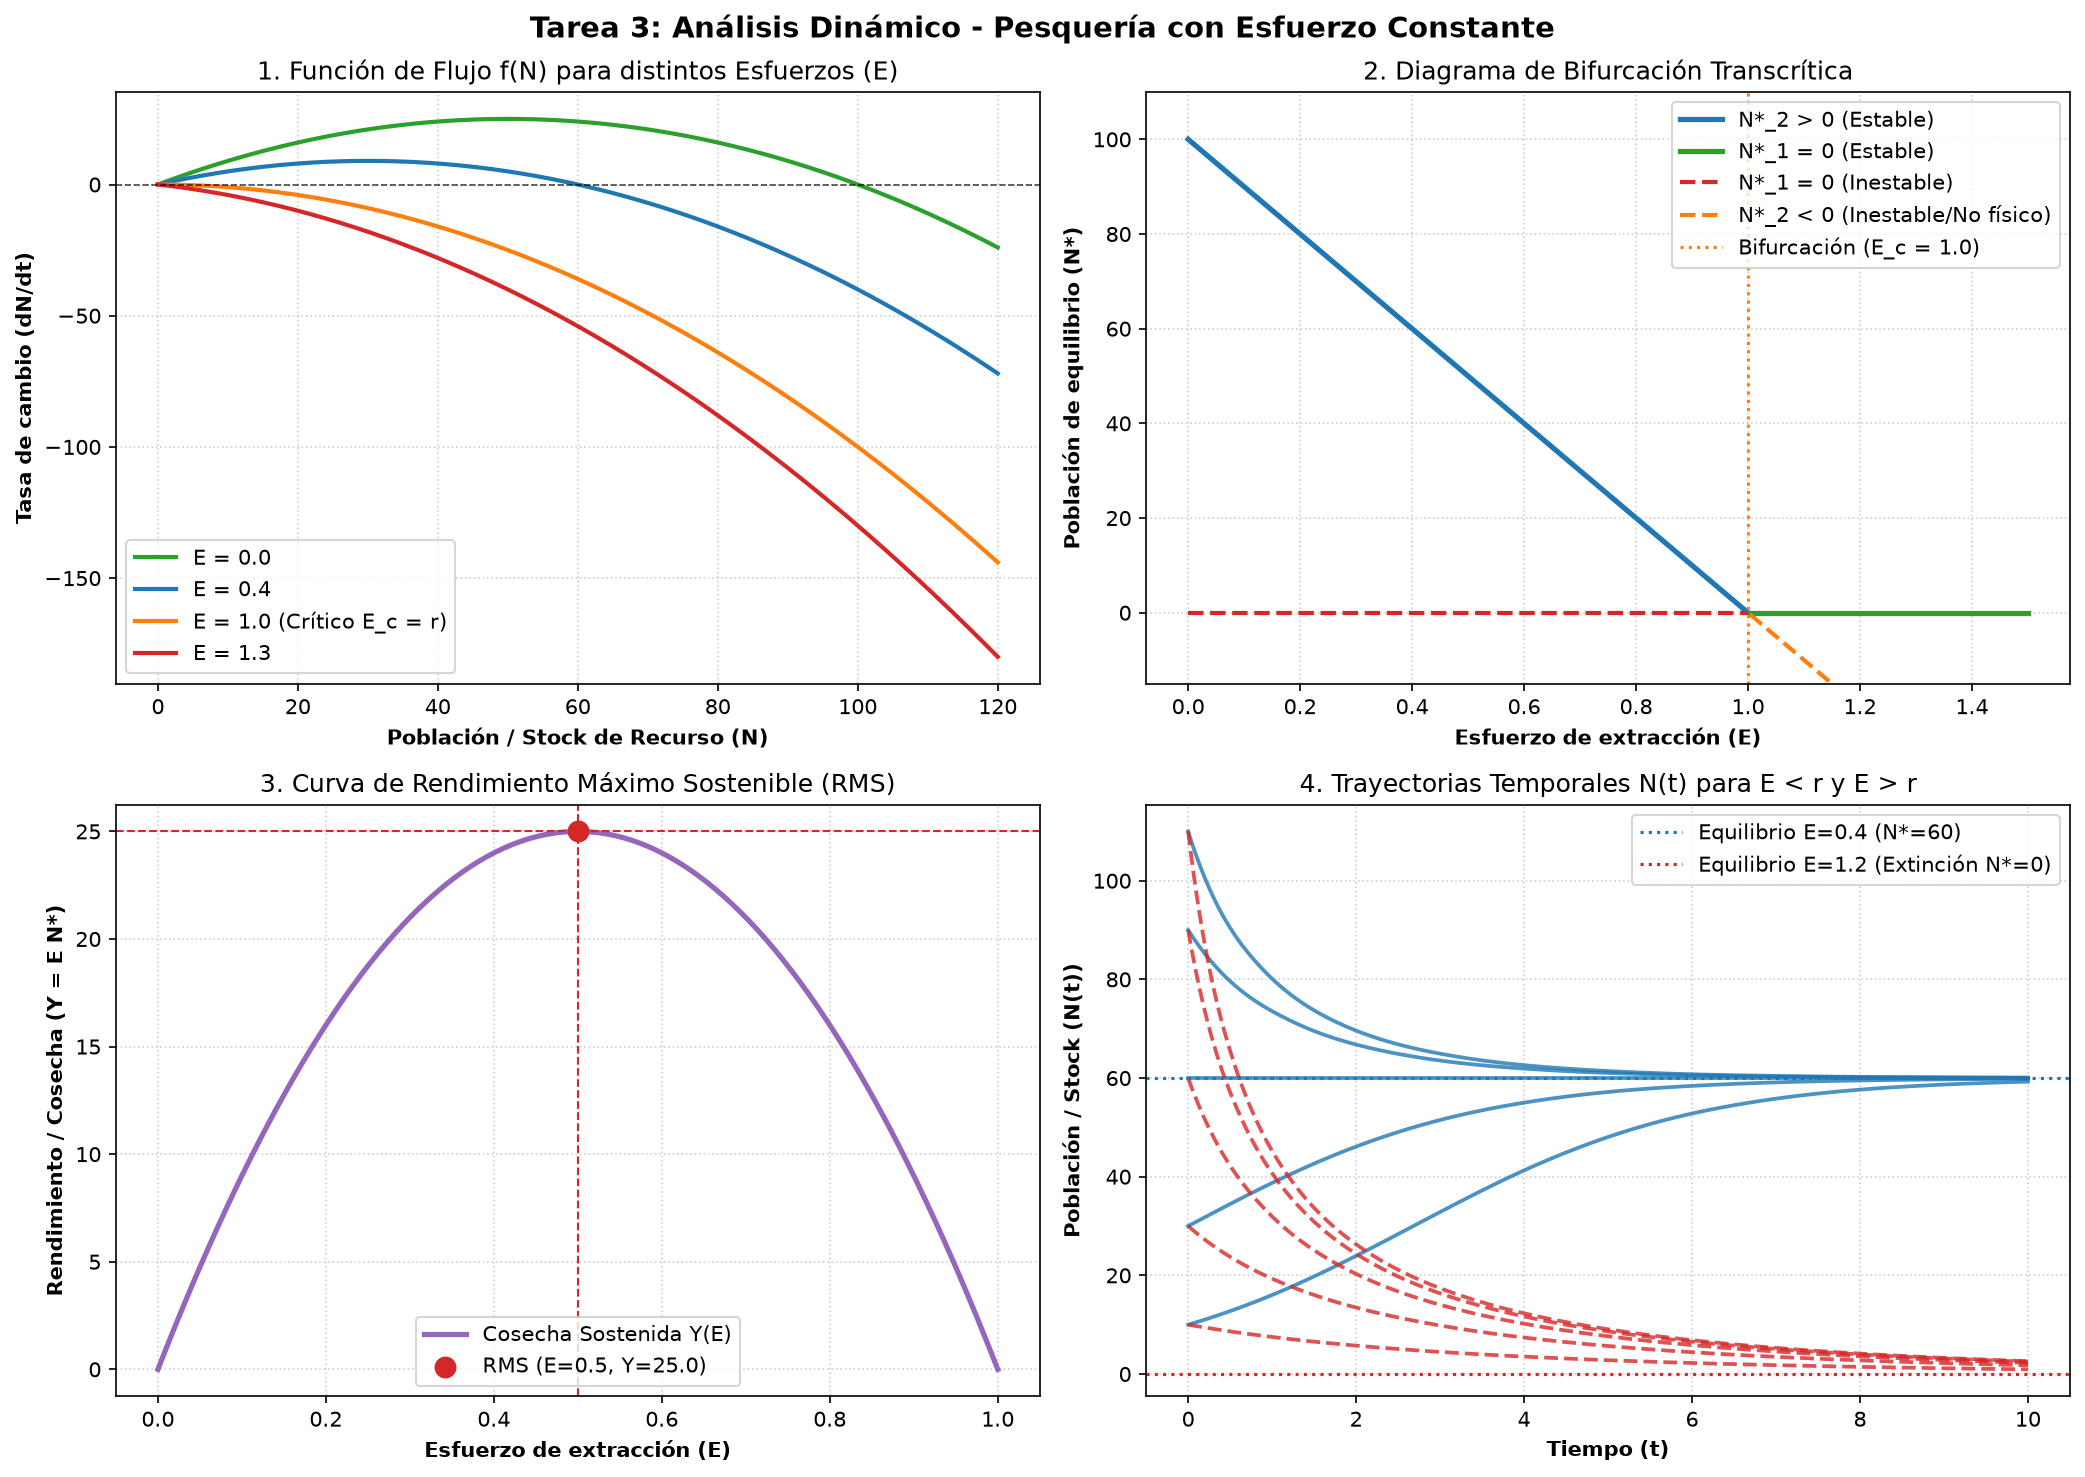

In [35]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Configuración de parámetros del modelo "estudiante 6" ---
# Los valores numéricos son arbitrarios para el análisis cualitativo
# Lo que dertermina la dinámica son las RELACIONES entre parámetros (E/r, E_c=r)
r = 1.0      # Tasa de crecimiento intrínseca
             # E_c=r=1.0 (bifurcación transcrítica)
             # E_RMS=r/2=0.5 (esfuerzo óptimo)
K = 100.0    # Capacidad de carga del ecosistema/acuífero
             # N*_RMS=k/2=50 (sotck en el óptimo)
             # Y_RMS=rK/4=25 (cosecha máx. sostenible)

# Ecuación diferencial del modelo de pesquería / recurso renovable
def modelo_pesqueria(t, N, E, r, K):
    """
    Ecuación diferencial del modelo de pesquería con esfuerzo constante.
    
    Ṅ = rN(1 - N/K) - EN
    
    Parámetros
    ----------
    t : float        → tiempo (requerido por solve_ivp, no aparece explícitamente)
    N : float        → stock actual del recurso
    E : float        → esfuerzo de extracción (parámetro de control)
    r : float        → tasa de crecimiento intrínseca
    K : float        → capacidad de carga
    
    Retorna
    -------
    dN/dt : tasa de cambio del stock en el instante t
    """
    return r * N * (1.0 - N / K) - E * N

# Crear figura de 2x2 para abarcar los 4 análisis del modelo
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)
fig.suptitle('Tarea 3: Análisis Dinámico - Pesquería con Esfuerzo Constante', fontsize=14, fontweight='bold')

# Desempaquetar la matriz de 2x2 subpaneles en 4 variables individuales
ax1, ax2, ax3, ax4 = axes.flatten()

# --- 1. PANEL 1: Función de Flujo f(N) ---
# Muestra cómo varía dN/dt en función del stock N para distintos esfuerzos E.
# Los cruces con el eje horizontal (f=0) son los puntos fijos N*.
# La PENDIENTE en cada cruce determina estabilidad: pendiente < 0 → estable.
N_vals = np.linspace(0, 120, 500)
esfuerzos = [0.0, 0.4, r, 1.3]
colores_flujo = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']

for E, col in zip(esfuerzos, colores_flujo):
    f_N = r * N_vals * (1.0 - N_vals / K) - E * N_vals
    label_txt = f'E = {E}' + (' (Crítico E_c = r)' if E == r else '')
    ax1.plot(N_vals, f_N, label=label_txt, color=col, linewidth=2)

ax1.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
ax1.set_xlabel('Población / Stock de Recurso (N)', fontweight='bold')
ax1.set_ylabel('Tasa de cambio (dN/dt)', fontweight='bold')
ax1.set_title('1. Función de Flujo f(N) para distintos Esfuerzos (E)')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# --- 2. PANEL 2: Diagrama de Bifurcación Transcrítica ---
# Muestra N* como función del parámetro de control E.
# En E_c = r, las dos ramas se cruzan: bifurcación transcrítica.
# Línea sólida = estable | línea punteada = inestable | naranja = no físico (N*<0)
E_arr = np.linspace(0, 1.5, 300)
N_est_pos = K * (1.0 - E_arr / r)

ax2.plot(E_arr[E_arr < r], N_est_pos[E_arr < r], color='#1f77b4', linewidth=2.5, label='N*_2 > 0 (Estable)')
ax2.plot(E_arr[E_arr >= r], np.zeros_like(E_arr[E_arr >= r]), color='#2ca02c', linewidth=2.5, label='N*_1 = 0 (Estable)')
ax2.plot(E_arr[E_arr < r], np.zeros_like(E_arr[E_arr < r]), color='#d62728', linestyle='--', linewidth=2, label='N*_1 = 0 (Inestable)')
ax2.plot(E_arr[E_arr >= r], N_est_pos[E_arr >= r], color='#ff7f0e', linestyle='--', linewidth=2, label='N*_2 < 0 (Inestable/No físico)')

ax2.axvline(r, color='#ff7f0e', linestyle=':', linewidth=1.5, label=f'Bifurcación (E_c = {r})')
ax2.set_xlabel('Esfuerzo de extracción (E)', fontweight='bold')
ax2.set_ylabel('Población de equilibrio (N*)', fontweight='bold')
ax2.set_title('2. Diagrama de Bifurcación Transcrítica')
ax2.set_ylim(-15, 110)
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

# --- 3. PANEL 3: Rendimiento Máximo Sostenible (RMS) ---
# Y(E) = E · N*₂ = EK(1 - E/r): parábola que se anula en E=0 y E=r.
# El máximo (RMS) se alcanza en E_RMS = r/2, con Y_RMS = rK/4.
# Zona verde: extracción sostenible (E < E_RMS).
# Zona roja: sobreexplotación (E_RMS < E < r) — rendimiento decreciente.
E_yield = np.linspace(0, r, 200)
Yield = E_yield * K * (1.0 - E_yield / r)

E_RMS = r / 2.0
Y_RMS = (r / 2.0) * K * (1.0 - (r / 2.0) / r)

ax3.plot(E_yield, Yield, color='#9467bd', linewidth=2.5, label='Cosecha Sostenida Y(E)')
ax3.scatter([E_RMS], [Y_RMS], color='#d62728', s=90, zorder=5, label=f'RMS (E={E_RMS}, Y={Y_RMS:.1f})')
ax3.axvline(E_RMS, color='#d62728', linestyle='--', linewidth=1)
ax3.axhline(Y_RMS, color='#d62728', linestyle='--', linewidth=1)

ax3.set_xlabel('Esfuerzo de extracción (E)', fontweight='bold')
ax3.set_ylabel('Rendimiento / Cosecha (Y = E N*)', fontweight='bold')
ax3.set_title('3. Curva de Rendimiento Máximo Sostenible (RMS)')
ax3.legend()
ax3.grid(True, linestyle=':', alpha=0.6)

# --- 4. PANEL 4: Simulación Temporal N(t) ---
# Se integra numéricamente la EDO para múltiples condiciones iniciales.
# Caso A (azul, E=0.4 < r): todas las trayectorias convergen a N*=60. Estable.
# Caso B (rojo, E=1.2 > r): todas las trayectorias colapsan a N*=0. Extinción.
t_span = (0, 10)
t_eval = np.linspace(0, 10, 300)
N_iniciales = [10.0, 30.0, 60.0, 90.0, 110.0]

# Caso A: Esfuerzo Sostenible (E = 0.4 < r)
E_sustentable = 0.4
for N0 in N_iniciales:
    sol = solve_ivp(modelo_pesqueria, t_span, [N0], args=(E_sustentable, r, K), t_eval=t_eval)
    ax4.plot(sol.t, sol.y[0], color='#1f77b4', alpha=0.8, linewidth=1.8)

# Caso B: Sobreesfuerzo / Colapso (E = 1.2 > r)
E_colapso = 1.2
for N0 in N_iniciales:
    sol_col = solve_ivp(modelo_pesqueria, t_span, [N0], args=(E_colapso, r, K), t_eval=t_eval)
    ax4.plot(sol_col.t, sol_col.y[0], color='#d62728', linestyle='--', alpha=0.8, linewidth=1.8)

# Indicadores de equilibrio esperado en el tiempo
N_eq_sust = K * (1.0 - E_sustentable / r)
ax4.axhline(N_eq_sust, color='#1f77b4', linestyle=':', label=f'Equilibrio E=0.4 (N*={N_eq_sust:.0f})')
ax4.axhline(0, color='#d62728', linestyle=':', label='Equilibrio E=1.2 (Extinción N*=0)')

ax4.set_xlabel('Tiempo (t)', fontweight='bold')
ax4.set_ylabel('Población / Stock (N(t))', fontweight='bold')
ax4.set_title('4. Trayectorias Temporales N(t) para E < r y E > r')
ax4.legend()
ax4.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()

# --- Guardar la figura en la carpeta actual ---
nombre_archivo = 'pesqueria_analisis.png'
plt.savefig(nombre_archivo, dpi=300, bbox_inches='tight')

ruta_absoluta = os.path.abspath(nombre_archivo)
print(f"\n[OK] El gráfico fue generado y guardado exitosamente en:\n{ruta_absoluta}\n")

plt.show()

---

### 5. Conexión con la clase — Alertas tempranas y gestión del recurso

El modelo muestra que operar con $E > E_{RMS} = r/2$ reduce el rendimiento 
aunque el recurso no colapse. La **alerta temprana** es la caída gradual de $N^*$:

$$N_2^* = K\left(1 - \frac{E}{r}\right) \xrightarrow{E \to r} 0$$

En analogía hidrológica: el nivel del acuífero baja lentamente conforme 
la extracción se acerca a la tasa de recarga. El colapso en $E_c = r$ no es 
abrupto como en una bifurcación saddle-node (no hay histéresis), 
pero sí es **irreversible** si el recurso llega a $N = 0$.

**Referencia:** Strogatz, S.H. (2018). *Nonlinear Dynamics and Chaos*, §3.7. 
Clark, C.W. (1990). *Mathematical Bioeconomics*, Wiley.